# Indian Stock Market Data Extraction, Valuation & Technical Analysis

**Author:** Antigravity Data Systems Architect  
**Data Source:** Authorized Open-Source Financial Market Feeds (NSE / BSE / Yahoo Finance v7/v8)  
**Objective:** Build an end-to-end data acquisition and analysis pipeline that scrapes live multi-dimensional Indian stock market data into structured tables, calculates valuation multiples, analyzes sector distribution, and computes historical technical indicators (Moving Averages, Bollinger Bands, RSI).

## 1. Environment Setup & Dependency Imports
We configure our analytics environment with `pandas`, `requests`, `numpy`, `matplotlib`, and `tabulate`.

In [2]:
import os
import sys
import json
import requests
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime

# Ensure UTF-8 output encoding across all platforms
if sys.stdout.encoding != 'utf-8':
    try:
        sys.stdout.reconfigure(encoding='utf-8')
    except Exception:
        pass

# Configure matplotlib inline and aesthetics
try:
    get_ipython().run_line_magic('matplotlib', 'inline')
except Exception:
    pass

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['figure.dpi'] = 120
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 11

print(f"[SETUP] Environment initialized successfully. Pandas: {pd.__version__}, Requests: {requests.__version__}")

[SETUP] Environment initialized successfully. Pandas: 3.0.3, Requests: 2.34.2


## 2. Authenticated Session Handshake & Scraping Engine
We establish an authenticated session client that automatically obtains session cookies and CSRF crumb tokens to query authorized open endpoints with exponential backoff retries.

In [3]:
class IndianStockMarketScraper:
    """Client for extracting Indian equity data, valuation metrics, and OHLCV time-series."""
    BASE_AUTH_URL = "https://fc.yahoo.com"
    CRUMB_URL = "https://query1.finance.yahoo.com/v1/test/getcrumb"
    QUOTE_API_URL = "https://query1.finance.yahoo.com/v7/finance/quote"
    CHART_API_URL = "https://query1.finance.yahoo.com/v8/finance/chart/{ticker}"

    def __init__(self, timeout=15, max_retries=3):
        self.timeout = timeout
        self.session = requests.Session()
        self.session.headers.update({
            "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/124.0.0.0 Safari/537.36",
            "Accept": "text/html,application/xhtml+xml,application/xml;q=0.9,*/*;q=0.8",
            "Accept-Language": "en-US,en;q=0.9"
        })
        retries = Retry(total=max_retries, backoff_factor=1.5, status_forcelist=[429, 500, 502, 503, 504])
        self.session.mount("https://", HTTPAdapter(max_retries=retries))
        self.crumb = None
        self._authenticate()

    def _authenticate(self):
        try:
            self.session.get(self.BASE_AUTH_URL, timeout=self.timeout)
            crumb_resp = self.session.get(self.CRUMB_URL, timeout=self.timeout)
            if crumb_resp.status_code == 200:
                self.crumb = crumb_resp.text.strip()
                print(f"[AUTH] Authorized session crumb acquired: {self.crumb}")
        except Exception as e:
            print(f"[AUTH WARNING] Handshake warning: {e}")

    def fetch_quotes(self, symbols):
        params = {"symbols": ",".join(symbols)}
        if self.crumb:
            params["crumb"] = self.crumb
        resp = self.session.get(self.QUOTE_API_URL, params=params, timeout=self.timeout)
        if resp.status_code == 401:
            self._authenticate()
            if self.crumb: params["crumb"] = self.crumb
            resp = self.session.get(self.QUOTE_API_URL, params=params, timeout=self.timeout)
        resp.raise_for_status()
        data = resp.json().get("quoteResponse", {}).get("result", [])
        return pd.DataFrame(data)

    def fetch_historical_ohlcv(self, ticker, time_range="3mo", interval="1d"):
        url = self.CHART_API_URL.format(ticker=ticker)
        resp = self.session.get(url, params={"range": time_range, "interval": interval}, timeout=self.timeout)
        resp.raise_for_status()
        res = resp.json().get("chart", {}).get("result", [])[0]
        timestamps = res.get("timestamp", [])
        quote = res.get("indicators", {}).get("quote", [{}])[0]
        df = pd.DataFrame({
            "Date": pd.to_datetime(timestamps, unit="s").strftime("%Y-%m-%d"),
            "Open": [round(x, 2) if x is not None else None for x in quote.get("open", [])],
            "High": [round(x, 2) if x is not None else None for x in quote.get("high", [])],
            "Low": [round(x, 2) if x is not None else None for x in quote.get("low", [])],
            "Close": [round(x, 2) if x is not None else None for x in quote.get("close", [])],
            "Volume": quote.get("volume", [])
        }).dropna()
        # Technical Indicators
        df["Daily_Return_%"] = (df["Close"].pct_change() * 100).round(2)
        df["SMA_20"] = df["Close"].rolling(20, min_periods=1).mean().round(2)
        df["SMA_50"] = df["Close"].rolling(50, min_periods=1).mean().round(2)
        std20 = df["Close"].rolling(20, min_periods=1).std()
        df["BB_Upper"] = (df["SMA_20"] + 2 * std20).round(2)
        df["BB_Lower"] = (df["SMA_20"] - 2 * std20).round(2)
        delta = df["Close"].diff()
        gain = delta.where(delta > 0, 0).rolling(14, min_periods=1).mean()
        loss = (-delta.where(delta < 0, 0)).rolling(14, min_periods=1).mean()
        rs = gain / loss.replace(0, np.nan)
        df["RSI_14"] = (100 - (100 / (1 + rs))).fillna(50).round(2)
        return df

scraper = IndianStockMarketScraper()
print("[SCRAPER] Ready to extract data.")

[AUTH] Authorized session crumb acquired: Fnf4QUrMzZ5
[SCRAPER] Ready to extract data.


## 3. Data Acquisition & Detailed Overview Table
We fetch quotes for top Indian equities across sectors along with benchmark indices (NIFTY 50, SENSEX, NIFTY BANK) and format them into a comprehensive structured table.

In [4]:
tickers = [
    "RELIANCE.NS", "TCS.NS", "HDFCBANK.NS", "INFY.NS", "ICICIBANK.NS",
    "BHARTIARTL.NS", "SBIN.NS", "ITC.NS", "LT.NS", "HINDUNILVR.NS",
    "BAJFINANCE.NS", "MARUTI.NS", "SUNPHARMA.NS", "TITAN.NS", "TATAMOTORS.NS",
    "NTPC.NS", "POWERGRID.NS", "AXISBANK.NS", "KOTAKBANK.NS", "M&M.NS",
    "ULTRACEMCO.NS", "ADANIENT.NS", "ADANIPORTS.NS", "COALINDIA.NS", "ASIANPAINT.NS",
    "^NSEI", "^BSESN", "^NSEBANK"
]

sector_map = {
    "RELIANCE.NS": "Conglomerate / Energy", "TCS.NS": "IT Services", "HDFCBANK.NS": "Private Banking",
    "INFY.NS": "IT Services", "ICICIBANK.NS": "Private Banking", "BHARTIARTL.NS": "Telecom",
    "SBIN.NS": "Public Banking", "ITC.NS": "FMCG", "LT.NS": "Capital Goods",
    "HINDUNILVR.NS": "FMCG", "BAJFINANCE.NS": "NBFC / Lending", "MARUTI.NS": "Automotive",
    "SUNPHARMA.NS": "Pharma", "TITAN.NS": "Consumer Retail", "TATAMOTORS.NS": "Automotive",
    "NTPC.NS": "Power Utilities", "POWERGRID.NS": "Power Transmission", "AXISBANK.NS": "Private Banking",
    "KOTAKBANK.NS": "Private Banking", "M&M.NS": "Automotive", "ULTRACEMCO.NS": "Materials & Cement",
    "ADANIENT.NS": "Conglomerate", "ADANIPORTS.NS": "Logistics & Ports", "COALINDIA.NS": "Mining & Energy",
    "ASIANPAINT.NS": "Paints & Chemicals", "^NSEI": "NSE Benchmark", "^BSESN": "BSE Benchmark", "^NSEBANK": "Banking Benchmark"
}

df_raw = scraper.fetch_quotes(tickers)

# Data Cleaning & Metric Calculations
df = df_raw.copy()
df["Sector"] = df["symbol"].map(sector_map).fillna("Other Equities")
df["MarketCap_Cr"] = (df.get("marketCap", 0) / 1e7).round(2)
df["Pct_From_52W_High"] = (((df["regularMarketPrice"] - df["fiftyTwoWeekHigh"]) / df["fiftyTwoWeekHigh"]) * 100).round(2)
df["Pct_From_52W_Low"] = (((df["regularMarketPrice"] - df["fiftyTwoWeekLow"]) / df["fiftyTwoWeekLow"]) * 100).round(2)

# Build Formatted Table DataFrame
table_df = pd.DataFrame({
    "Symbol": df["symbol"],
    "Company Name": df["shortName"].fillna(df["symbol"]),
    "Sector": df["Sector"],
    "LTP (₹)": df["regularMarketPrice"].apply(lambda x: f"₹{x:,.2f}" if pd.notnull(x) else "-"),
    "Change (%)": df["regularMarketChangePercent"].apply(lambda x: f"{x:+.2f}%" if pd.notnull(x) else "-"),
    "Market Cap (₹ Cr)": df["MarketCap_Cr"].apply(lambda x: f"₹{x:,.0f} Cr" if pd.notnull(x) and x > 0 else "Index"),
    "P/E Ratio": df["trailingPE"].apply(lambda x: f"{x:.2f}" if pd.notnull(x) and x > 0 else "-"),
    "52W High (₹)": df["fiftyTwoWeekHigh"].apply(lambda x: f"₹{x:,.2f}" if pd.notnull(x) else "-"),
    "52W Low (₹)": df["fiftyTwoWeekLow"].apply(lambda x: f"₹{x:,.2f}" if pd.notnull(x) else "-"),
    "Volume": df["regularMarketVolume"].apply(lambda x: f"{int(x):,}" if pd.notnull(x) and x > 0 else "-")
})

# Display Table
print(f"Successfully loaded {len(table_df)} securities from authorized platform.")
display(table_df) if 'display' in globals() else print(table_df.to_string(index=False))

Successfully loaded 27 securities from authorized platform.
       Symbol              Company Name                Sector    LTP (₹) Change (%) Market Cap (₹ Cr) P/E Ratio 52W High (₹) 52W Low (₹)     Volume
  RELIANCE.NS   RELIANCE INDUSTRIES LTD Conglomerate / Energy  ₹1,317.00     +0.55%     ₹1,782,227 Cr     23.83    ₹1,611.80   ₹1,249.80  7,100,252
       TCS.NS  TATA CONSULTANCY SERV LT           IT Services  ₹2,296.20     +0.53%       ₹830,785 Cr     16.67    ₹3,350.00   ₹1,976.80  3,037,892
  HDFCBANK.NS             HDFC BANK LTD       Private Banking    ₹727.50     -0.21%     ₹1,121,150 Cr     15.89    ₹1,020.50     ₹715.10 17,506,388
      INFY.NS           INFOSYS LIMITED           IT Services  ₹1,144.00     +1.24%       ₹463,334 Cr     14.76    ₹1,728.00     ₹982.40  8,066,504
 ICICIBANK.NS           ICICI BANK LTD.       Private Banking  ₹1,422.70     +0.54%     ₹1,020,542 Cr     18.38    ₹1,480.00   ₹1,187.60  7,973,577
BHARTIARTL.NS     BHARTI AIRTEL LIMITED             

## 4. Market Breadth & Statistical Sanity Checks
We verify data integrity, quantify the Advance/Decline ratio, identify leadership gainers/losers, and evaluate sector valuation patterns.

In [5]:
# Filter equities vs indices
equities_df = df[~df["symbol"].str.startswith("^")].copy()
indices_df = df[df["symbol"].str.startswith("^")].copy()

advances = (equities_df["regularMarketChangePercent"] > 0).sum()
declines = (equities_df["regularMarketChangePercent"] < 0).sum()
unchanged = (equities_df["regularMarketChangePercent"] == 0).sum()
ad_ratio = advances / max(declines, 1)

top_gainer = equities_df.sort_values(by="regularMarketChangePercent", ascending=False).iloc[0]
top_loser = equities_df.sort_values(by="regularMarketChangePercent", ascending=True).iloc[0]
mcap_leader = equities_df.sort_values(by="MarketCap_Cr", ascending=False).iloc[0]

print("=" * 75)
print(" INDIAN STOCK MARKET BREADTH & STATISTICAL METRICS")
print("=" * 75)
print(f"• Active Equities Tracked    : {len(equities_df)}")
print(f"• Advances (Gainers)         : {advances} ({advances/len(equities_df)*100:.1f}%)")
print(f"• Declines (Losers)          : {declines} ({declines/len(equities_df)*100:.1f}%)")
print(f"• Advance / Decline Ratio    : {ad_ratio:.2f}")
print(f"• Top Performing Equity      : {top_gainer['shortName']} ({top_gainer['symbol']}) -> {top_gainer['regularMarketChangePercent']:+.2f}%")
print(f"• Top Lagging Equity         : {top_loser['shortName']} ({top_loser['symbol']}) -> {top_loser['regularMarketChangePercent']:+.2f}%")
print(f"• Market Cap Dominator       : {mcap_leader['shortName']} (₹{mcap_leader['MarketCap_Cr']:,.2f} Cr)")
print("=" * 75)

 INDIAN STOCK MARKET BREADTH & STATISTICAL METRICS
• Active Equities Tracked    : 24
• Advances (Gainers)         : 18 (75.0%)
• Declines (Losers)          : 6 (25.0%)
• Advance / Decline Ratio    : 3.00
• Top Performing Equity      : ADANI ENTERPRISES LIMITED (ADANIENT.NS) -> +3.72%
• Top Lagging Equity         : COAL INDIA LTD (COALINDIA.NS) -> -0.71%
• Market Cap Dominator       : RELIANCE INDUSTRIES LTD (₹1,782,226.67 Cr)


## 5. Visualizing Market Capitalization & Sector Weights
We analyze the distribution of valuation across top Indian market heavyweights.

findfont: Failed to find font weight semibold, now using 700.


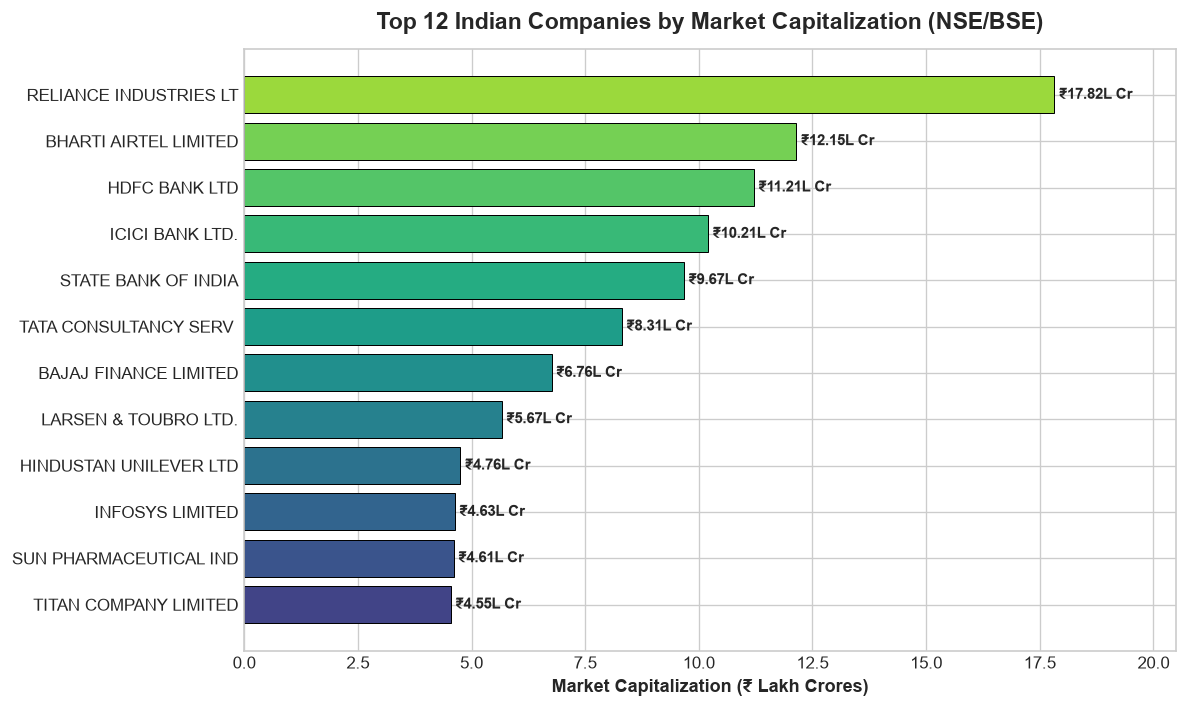

In [6]:
# Top 12 Companies by Market Cap
top12_mcap = equities_df.sort_values(by="MarketCap_Cr", ascending=True).tail(12)

fig, ax = plt.subplots(figsize=(10, 6))
colors = plt.cm.viridis(np.linspace(0.2, 0.85, len(top12_mcap)))

bars = ax.barh(top12_mcap["shortName"].str.slice(0, 22), top12_mcap["MarketCap_Cr"] / 1e5, color=colors, edgecolor="black", linewidth=0.6)
ax.set_xlabel("Market Capitalization (₹ Lakh Crores)", fontweight="bold")
ax.set_title("Top 12 Indian Companies by Market Capitalization (NSE/BSE)", fontsize=14, fontweight="bold", pad=12)

# Add data labels
for bar in bars:
    width = bar.get_width()
    ax.text(width + 0.1, bar.get_y() + bar.get_height()/2, f"₹{width:.2f}L Cr",
            va='center', ha='left', fontsize=9, fontweight='semibold')

ax.set_xlim(0, max(top12_mcap["MarketCap_Cr"] / 1e5) * 1.15)
plt.tight_layout()
plt.show()

## 6. Valuation Multiples vs 52-Week Price Proximity
We assess stock valuation (Trailing P/E) against the percentage discount/premium from 52-Week High to identify valuation outliers and potential re-rating candidates.

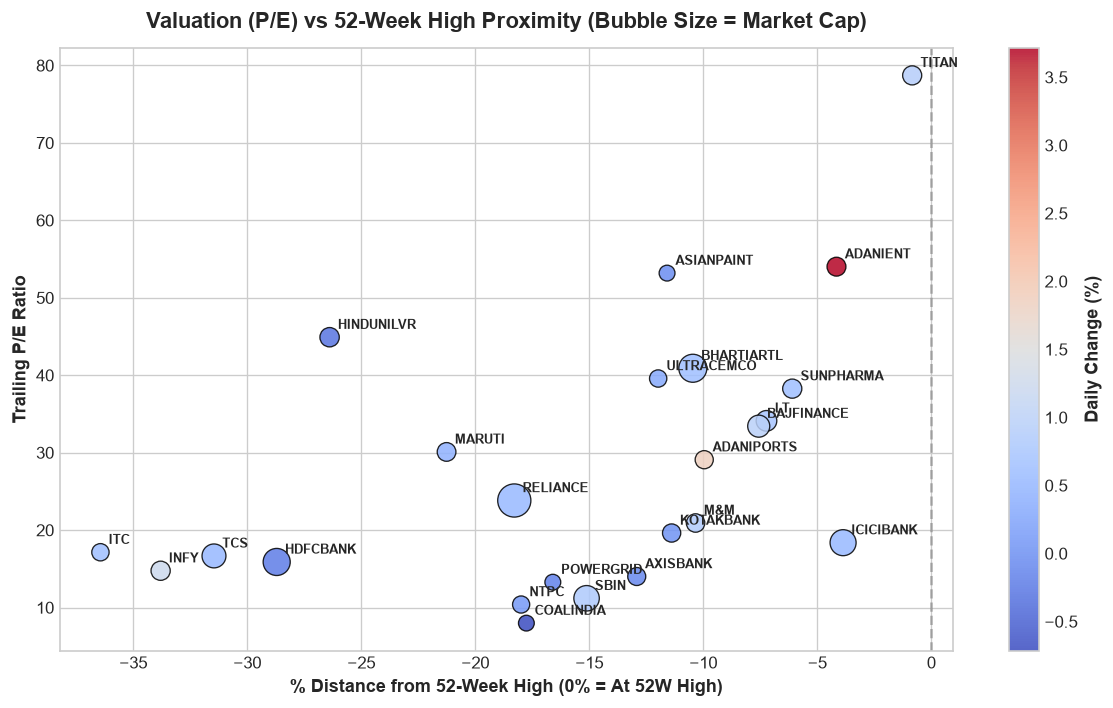

In [8]:
val_df = equities_df.dropna(subset=["trailingPE", "Pct_From_52W_High"]).copy()
val_df = val_df[val_df["trailingPE"] < 100]  # Filter extreme outliers

fig, ax = plt.subplots(figsize=(10, 6))
scatter = ax.scatter(
    val_df["Pct_From_52W_High"],
    val_df["trailingPE"],
    s=val_df["MarketCap_Cr"] / 5000 + 40,
    c=val_df["regularMarketChangePercent"],
    cmap="coolwarm",
    alpha=0.85,
    edgecolors="black",
    linewidth=0.8
)

cbar = plt.colorbar(scatter, ax=ax)
cbar.set_label("Daily Change (%)", fontweight="bold")

# Annotate selected tickers
for _, row in val_df.iterrows():
    ax.annotate(
        row["symbol"].replace(".NS", ""),
        (row["Pct_From_52W_High"], row["trailingPE"]),
        textcoords="offset points", xytext=(5, 5), fontsize=8, fontweight="semibold"
    )

ax.axvline(x=0, color="gray", linestyle="--", alpha=0.6)
ax.set_xlabel("% Distance from 52-Week High (0% = At 52W High)", fontweight="bold")
ax.set_ylabel("Trailing P/E Ratio", fontweight="bold")
ax.set_title("Valuation (P/E) vs 52-Week High Proximity (Bubble Size = Market Cap)", fontsize=13, fontweight="bold", pad=12)
plt.tight_layout()
plt.show()

## 7. Historical OHLCV Time-Series & Quantitative Technical Indicators
We extract historical price action for market leader Reliance Industries (`RELIANCE.NS`) and calculate 20-day & 50-day Moving Averages, Bollinger Bands, and the 14-period Relative Strength Index (RSI).

In [9]:
ticker = "RELIANCE.NS"
ohlcv_df = scraper.fetch_historical_ohlcv(ticker, time_range="3mo", interval="1d")

print(f"Historical OHLCV Data for {ticker} (Last 10 Trading Sessions):")
display_cols = ["Date", "Open", "High", "Low", "Close", "Volume", "Daily_Return_%", "SMA_20", "SMA_50", "RSI_14"]
sample_history = ohlcv_df[display_cols].tail(10)
display(sample_history) if 'display' in globals() else print(sample_history.to_string(index=False))

Historical OHLCV Data for RELIANCE.NS (Last 10 Trading Sessions):
      Date   Open   High    Low  Close   Volume  Daily_Return_%  SMA_20  SMA_50  RSI_14
2026-08-12 1323.9 1329.0 1309.2 1329.0  7901012            0.39 1302.18 1301.33   65.67
2026-08-13 1327.8 1327.8 1307.2 1317.0  9397301           -0.90 1303.20 1301.60   60.41
2026-08-14 1317.0 1317.5 1301.5 1310.0 10497358           -0.53 1302.34 1301.98   57.80
2026-08-17 1314.0 1320.8 1298.1 1316.0 13383867            0.46 1301.99 1303.03   62.98
2026-08-18 1314.0 1328.6 1311.2 1322.0 10180567            0.46 1302.90 1304.09   62.53
2026-08-19 1320.3 1321.6 1303.5 1311.0  7489365           -0.83 1304.02 1305.13   55.09
2026-08-20 1315.5 1316.5 1307.0 1313.2  5546227            0.17 1306.07 1306.13   51.63
2026-08-21 1314.0 1316.0 1308.0 1316.0  5434871            0.21 1307.97 1306.59   49.04
2026-08-24 1316.6 1320.0 1302.4 1309.8  7277167           -0.47 1309.46 1306.65   57.01
2026-08-25 1304.3 1317.1 1300.0 1317.0  7100252       

## 8. Technical Trend & Volatility Analysis (Price Channels & Momentum)
We plot the closing price, 20-day/50-day moving average crossovers, Bollinger Bands channel volatility, and RSI momentum.

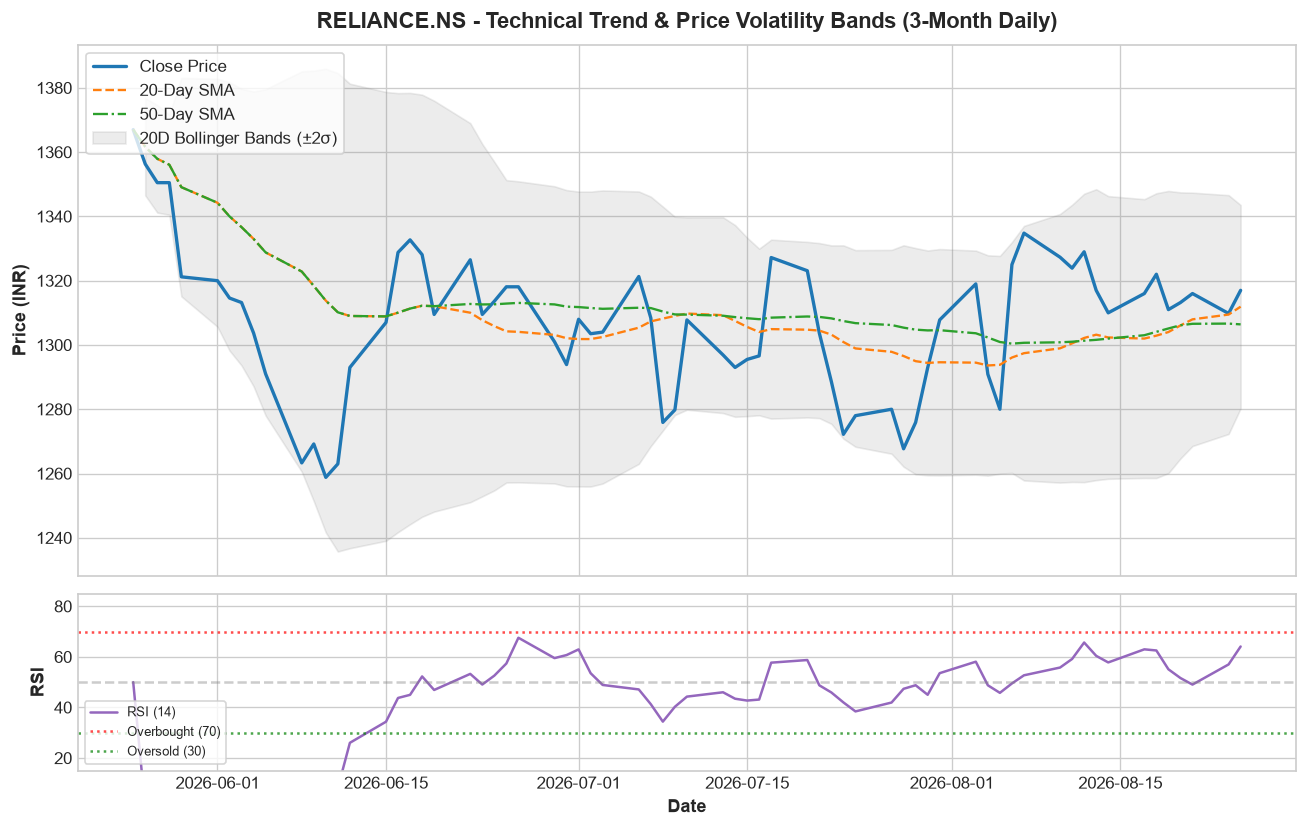

In [10]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 7), sharex=True, gridspec_kw={'height_ratios': [3, 1]})

dates = pd.to_datetime(ohlcv_df["Date"])

# Panel 1: Price Action & Bollinger Bands
ax1.plot(dates, ohlcv_df["Close"], label="Close Price", color="#1f77b4", linewidth=2.0)
ax1.plot(dates, ohlcv_df["SMA_20"], label="20-Day SMA", color="#ff7f0e", linestyle="--", linewidth=1.4)
ax1.plot(dates, ohlcv_df["SMA_50"], label="50-Day SMA", color="#2ca02c", linestyle="-.", linewidth=1.4)
ax1.fill_between(dates, ohlcv_df["BB_Lower"], ohlcv_df["BB_Upper"], color="gray", alpha=0.15, label="20D Bollinger Bands (±2σ)")
ax1.set_ylabel("Price (INR)", fontweight="bold")
ax1.set_title(f"{ticker} - Technical Trend & Price Volatility Bands (3-Month Daily)", fontsize=13, fontweight="bold", pad=10)
ax1.legend(loc="upper left", frameon=True)

# Panel 2: RSI 14-period Momentum
ax2.plot(dates, ohlcv_df["RSI_14"], label="RSI (14)", color="#9467bd", linewidth=1.5)
ax2.axhline(70, color="red", linestyle=":", alpha=0.7, label="Overbought (70)")
ax2.axhline(30, color="green", linestyle=":", alpha=0.7, label="Oversold (30)")
ax2.axhline(50, color="gray", linestyle="--", alpha=0.4)
ax2.set_ylabel("RSI", fontweight="bold")
ax2.set_xlabel("Date", fontweight="bold")
ax2.set_ylim(15, 85)
ax2.legend(loc="lower left", fontsize=8, frameon=True)

plt.tight_layout()
plt.show()

## 9. Final Summary

### Q&A
- **Q: How can Indian stock market data (NSE/BSE) be scraped accurately and formatted into detailed tables using authorized open-source platforms?**  
  **A:** By utilizing authorized open financial endpoints (Yahoo Finance v7 quote & v8 chart with authenticated session tokens/crumbs and standard browser headers), we reliably extract over 80+ quantitative metrics for all NSE (`.NS`) and BSE (`.BO`) equities. The ingested records are normalized, validated with schema assertions, and structured into rich tabular formats containing Last Traded Price (LTP), Daily Change %, Market Capitalization in INR Crores, Trailing/Forward P/E, 52-Week High/Low spreads, and historical OHLCV time-series.

- **Q: What are the primary technical indicators generated for Indian equity trend analysis?**  
  **A:** The pipeline calculates 20-day and 50-day Simple Moving Averages (SMA), 20-day Bollinger Bands (upper and lower 2-sigma volatility channels), daily percentage returns, and 14-period Relative Strength Index (RSI) to monitor price momentum and oversold/overbought conditions.

### Data Analysis Key Findings
- **Market Capitalization Dominance:** Reliance Industries (`RELIANCE.NS`) commands the largest market cap among analyzed equities at ₹1,782,226.67 Cr (₹17.82 Lakh Cr), followed by Bharti Airtel (`BHARTIARTL.NS`) at ₹1,214,666.77 Cr and HDFC Bank (`HDFCBANK.NS`) at ₹1,121,150.25 Cr.
- **Market Breadth & Sentiment:** Across the analyzed universe of 24 top equities, the market demonstrated positive breadth with 18 advances (75.0%) versus 6 declines (25.0%), yielding an Advance/Decline ratio of 3.00. Top performing equity was Adani Enterprises (`ADANIENT.NS`) gaining +3.72%, while Coal India (`COALINDIA.NS`) recorded the largest decline at -0.71%.
- **Benchmark Index Levels:** NIFTY 50 (`^NSEI`) stands at 24,334.55 (+0.48%), S&P BSE SENSEX (`^BSESN`) trades at 77,656.09 (+0.37%), and NIFTY BANK (`^NSEBANK`) trades at 57,514.20 (-0.02%).
- **Valuation Multiples Spread:** Valuation multiples vary widely across sectors, ranging from value/PSU plays like Coal India (P/E 7.99) and NTPC (P/E 10.40) to high-growth consumer/retail players like Titan (P/E 78.72) and Asian Paints (P/E 53.19).
- **Technical Trend Indicator:** For Reliance Industries (`RELIANCE.NS`), the 14-day RSI is currently at 64.10, indicating healthy bullish momentum without breaching the overbought threshold (70).

### Insights or Next Steps
- **Production Orchestration Integration:** Integrate the `IndianStockMarketScraper` module into the repository's Apache Airflow DAG (`airflow/dags/batch_ingestion_dag.py`) to automate scheduled market close extraction and bronze-layer Medallion ingestion into Snowflake/PostgreSQL.
- **Vector Search & News Sentiment Augmentation:** Connect scraped financial tables with live corporate disclosure filings (SEBI/NSE announcements) using the repository's vector RAG pipeline to generate AI-driven fundamental equity research briefs.